# Laboratorio 10: Explicabilidad en datos tabulares con SHAP, LIME y contrafactuales

Este notebook se sitúa en el equipo de riesgo de modelo de una entidad financiera que debe justificar decisiones de crédito. Sobre un clasificador de gradient boosting entrenado con German Credit se calculan valores SHAP y se verifican con la fórmula de Shapley (Task 2), se implementa LIME desde cero y se construyen explicaciones contrafactuales (Task 3).

Las funciones reutilizables se encuentran en `src/tabular/`. El notebook está pensado para ejecutarse en Google Colab.

## Configuración

La siguiente celda clona el repositorio cuando el notebook se ejecuta en Colab, agrega su carpeta raíz al `sys.path` e instala la librería `shap`.

In [1]:
import os
import sys

REPO_URL = "https://github.com/Tunchxz/CC3092-Laboratorio-10.git"
ROOT = "/content/CC3092-Laboratorio-10"

if "google.colab" in sys.modules:
    if not os.path.isdir(ROOT):
        !git clone -q {REPO_URL} {ROOT}
    %pip install -q shap
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.stats import spearmanr
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, roc_auc_score

from src.tabular.data import SEED, decode, load_credit, log_odds_fn, proba_fn, split, train_gbm
from src.tabular.shap_utils import tree_shap
from src.tabular.shapley import coalition_values, shapley_from_values
from src.tabular.lime_tabular import lime_explain, mean_pairwise_jaccard
from src.tabular.counterfactuals import distance, generate_candidates, mad_scale, select_diverse

warnings.filterwarnings("ignore", category=FutureWarning)
rng = np.random.default_rng(SEED)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
print(f"Semilla aleatoria: {SEED} | shap {shap.__version__}")


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-z))

Semilla aleatoria: 42 | shap 0.52.0


## Task 2 - SHAP

### Task 2.1. Datos y modelo

Se descarga German Credit con `fetch_openml`. La clase `good` se codifica como 1 y `bad` como 0, y las 13 variables categóricas se codifican con `OrdinalEncoder`.

> **Limitación.** Los códigos ordinales son arbitrarios (por ejemplo, el orden alfabético de las categorías), pero el modelo los trata como números. Los árboles pueden cortar entre códigos que no tienen un orden real, y las explicaciones que hablan de "valores altos" o "valores bajos" de una variable categórica no tienen un significado sustantivo.

El conjunto se divide en 80% de entrenamiento y 20% de prueba de forma estratificada, y se entrena un `GradientBoostingClassifier` con los siguientes valores.

| Parámetro | Valor |
| :-------- | :---: |
| Semilla aleatoria | 42 |
| Número de árboles | 200 |
| Profundidad máxima de cada árbol | 3 |
| Tamaño del fondo para SHAP | 100 instancias |

In [3]:
X, y, encoder, categorical, numeric = load_credit()
cols = list(X.columns)
print(f"{X.shape[0]} solicitudes, {X.shape[1]} variables ({len(numeric)} numéricas y {len(categorical)} categóricas)")
print(f"Numéricas: {numeric}")
X.head()

1000 solicitudes, 20 variables (7 numéricas y 13 categóricas)
Numéricas: ['duration', 'credit_amount', 'installment_commitment', 'residence_since', 'age', 'existing_credits', 'num_dependents']


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,1,6,1,6,1169,4,3,4,3,2,4,3,67,1,1,2,1,1,1,1
1,0,48,3,6,5951,2,0,2,0,2,2,3,22,1,1,1,1,1,0,1
2,3,12,1,2,2096,2,1,2,3,2,3,3,49,1,1,1,3,2,0,1
3,1,42,3,3,7882,2,1,2,3,1,4,1,45,1,0,1,1,2,0,1
4,1,24,2,4,4870,2,0,3,3,2,4,2,53,1,0,2,1,2,0,1


In [4]:
X_train, X_test, y_train, y_test = split(X, y)
model = train_gbm(X_train, y_train)
f_logit = log_odds_fn(model, cols)
f_prob = proba_fn(model, cols)

p_test = model.predict_proba(X_test)[:, 1]
print(f"Entrenamiento: {len(X_train)} | prueba: {len(X_test)}")
print(f"Exactitud en prueba: {accuracy_score(y_test, (p_test >= 0.5).astype(int)):.4f}")
print(f"AUC en prueba:       {roc_auc_score(y_test, p_test):.4f}")

Entrenamiento: 800 | prueba: 200
Exactitud en prueba: 0.7750
AUC en prueba:       0.7650


**RESULTADOS**

El modelo obtiene una exactitud de 0.7750 y un AUC de 0.7650 sobre el conjunto de prueba.

### Task 2.2. Valores SHAP con TreeSHAP intervencional

Se calculan los valores SHAP del conjunto de prueba con `shap.TreeExplainer` en su versión intervencional, sobre la salida en log-odds (`model_output="raw"`) y con un fondo de 100 instancias de entrenamiento elegidas al azar.

In [5]:
bg_idx = rng.choice(len(X_train), size=100, replace=False)
background = X_train.iloc[bg_idx]

explanation, phi0 = tree_shap(model, X_test, background)
phi = explanation.values
f_test = model.decision_function(X_test)

print("1. Eficiencia")
print(f"   max |phi_0 + sum_j phi_j - f(x)| = {np.abs(phi0 + phi.sum(axis=1) - f_test).max():.3e}")
print("2. Valor base")
print(f"   phi_0                              = {phi0:.6f}")
print(f"   promedio de f(x) sobre el fondo    = {f_logit(background).mean():.6f}")

1. Eficiencia
   max |phi_0 + sum_j phi_j - f(x)| = 9.709e-08
2. Valor base
   phi_0                              = 1.430742
   promedio de f(x) sobre el fondo    = 1.430742


**RESULTADOS**

La eficiencia se cumple con un error absoluto máximo de $9.7 \times 10^{-8}$ sobre las 200 instancias de prueba, y el valor base (1.430742) coincide con el promedio de la salida en log-odds sobre el fondo hasta el sexto decimal.

**3. Importancia global.** Se compara $I_{j} = \frac{1}{N}\sum_{n}\left|\phi_{j}^{(n)}\right|$ con la importancia por permutación de scikit-learn sobre el conjunto de prueba (métrica AUC, 10 repeticiones).

In [6]:
perm = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=SEED)
importance = pd.DataFrame({
    "I_j (SHAP)": np.abs(phi).mean(axis=0),
    "permutación (media)": perm.importances_mean,
    "permutación (desv. est.)": perm.importances_std,
}, index=cols)
importance["ranking SHAP"] = importance["I_j (SHAP)"].rank(ascending=False).astype(int)
importance["ranking permutación"] = importance["permutación (media)"].rank(ascending=False).astype(int)

top5 = pd.DataFrame({
    "SHAP": importance["I_j (SHAP)"].nlargest(5).index,
    "permutación": importance["permutación (media)"].nlargest(5).index,
}, index=pd.RangeIndex(1, 6, name="posición"))
display(top5)
rho_rank = spearmanr(importance["I_j (SHAP)"], importance["permutación (media)"]).statistic
print(f"Correlación de Spearman entre los dos rankings completos: {rho_rank:.4f}")
importance.sort_values("ranking SHAP")

,SHAP,permutación
posición,,
1,checking_status,checking_status
2,purpose,credit_amount
3,credit_amount,duration
4,duration,credit_history
5,savings_status,savings_status


Correlación de Spearman entre los dos rankings completos: 0.6496


,I_j (SHAP),permutación (media),permutación (desv. est.),ranking SHAP,ranking permutación
checking_status,0.760287,0.119,0.0301472,1,1
purpose,0.511773,0.00380952,0.0106306,2,12
credit_amount,0.490238,0.0762619,0.0136096,3,2
duration,0.391748,0.0579167,0.0119568,4,3
savings_status,0.296328,0.0261548,0.0112148,5,5
age,0.288536,-0.00541667,0.00960711,6,20
credit_history,0.227777,0.0397143,0.011262,7,4
residence_since,0.20757,0.00217857,0.0132863,8,13
installment_commitment,0.198092,0.00986905,0.00485401,9,7
other_payment_plans,0.174898,0.020119,0.00339275,10,6


**RESULTADOS**

Las dos importancias coinciden en la primera variable (`checking_status`) y comparten cuatro de las cinco principales (`checking_status`, `credit_amount`, `duration` y `savings_status`). Las diferencias están en `purpose`, segunda por SHAP y duodécima por permutación, y en `credit_history`, cuarta por permutación y séptima por SHAP. La correlación de Spearman entre los rankings completos es 0.65.

**4. Explicaciones locales.** Se elige el primer cliente de prueba con probabilidad de `good` mayor que 0.8 y el primero con probabilidad menor que 0.2. En las cascadas, las variables categóricas se muestran decodificadas.

Cliente aprobado: fila 977 del conjunto original, posición 0 en prueba, p(good) = 0.8664, f(x) = 1.8693, clase real = good


,variable,valor,phi_j
0,savings_status,no known savings,0.915529
1,checking_status,0<=X<200,-0.410381
2,credit_amount,2427,0.393569


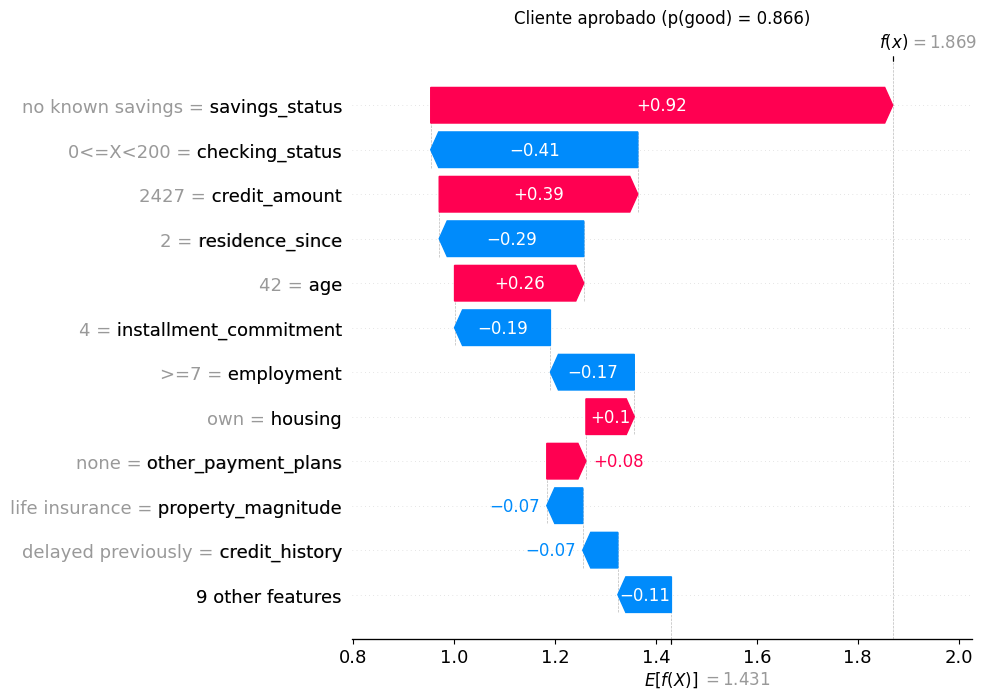

Cliente rechazado: fila 735 del conjunto original, posición 1 en prueba, p(good) = 0.0871, f(x) = -2.3490, clase real = good


,variable,valor,phi_j
0,duration,36,-0.925967
1,savings_status,no known savings,0.876684
2,other_payment_plans,bank,-0.806343


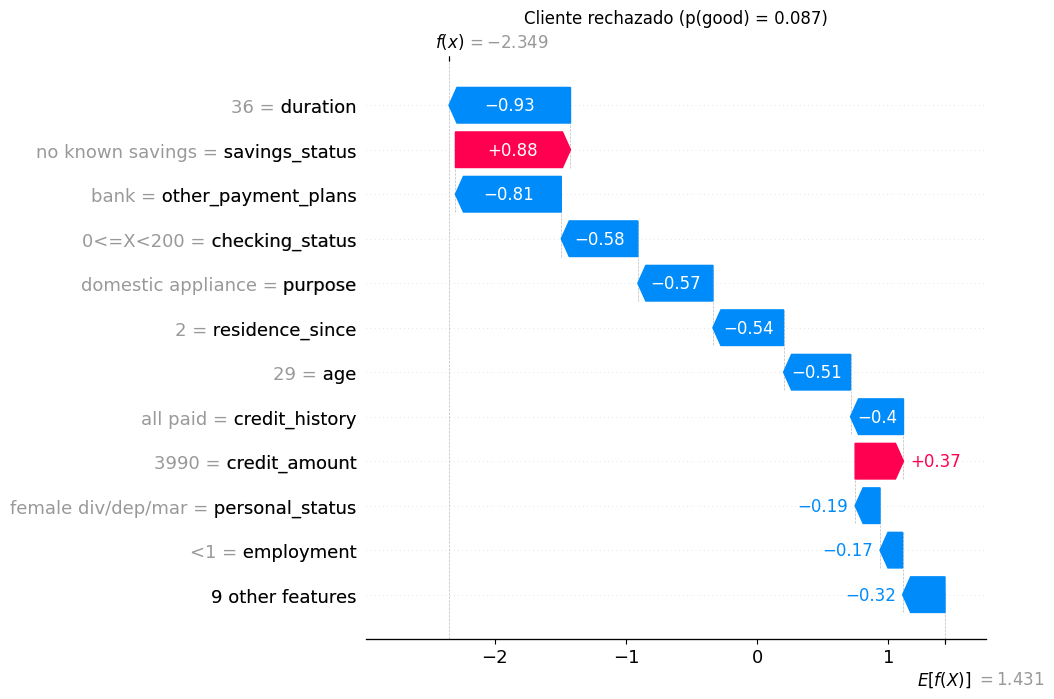

In [7]:
i_good = int(np.flatnonzero(p_test > 0.8)[0])
i_bad = int(np.flatnonzero(p_test < 0.2)[0])

X_test_display = X_test.copy().astype(object)
for col in categorical:
    X_test_display[col] = [decode(v, col, encoder, categorical) for v in X_test[col]]
explanation_display = shap.Explanation(values=phi, base_values=np.full(len(phi), phi0), data=X_test.values,
                                       display_data=X_test_display.values, feature_names=cols)

for label, i in (("aprobado", i_good), ("rechazado", i_bad)):
    print(f"Cliente {label}: fila {X_test.index[i]} del conjunto original, posición {i} en prueba, "
          f"p(good) = {p_test[i]:.4f}, f(x) = {f_test[i]:.4f}, clase real = {'good' if y_test.iloc[i] else 'bad'}")
    top3 = np.argsort(-np.abs(phi[i]))[:3]
    display(pd.DataFrame({
        "variable": [cols[j] for j in top3],
        "valor": [X_test_display.iloc[i, j] for j in top3],
        "phi_j": phi[i, top3],
    }))
    shap.plots.waterfall(explanation_display[i], max_display=12, show=False)
    plt.title(f"Cliente {label} (p(good) = {p_test[i]:.3f})")
    plt.show()

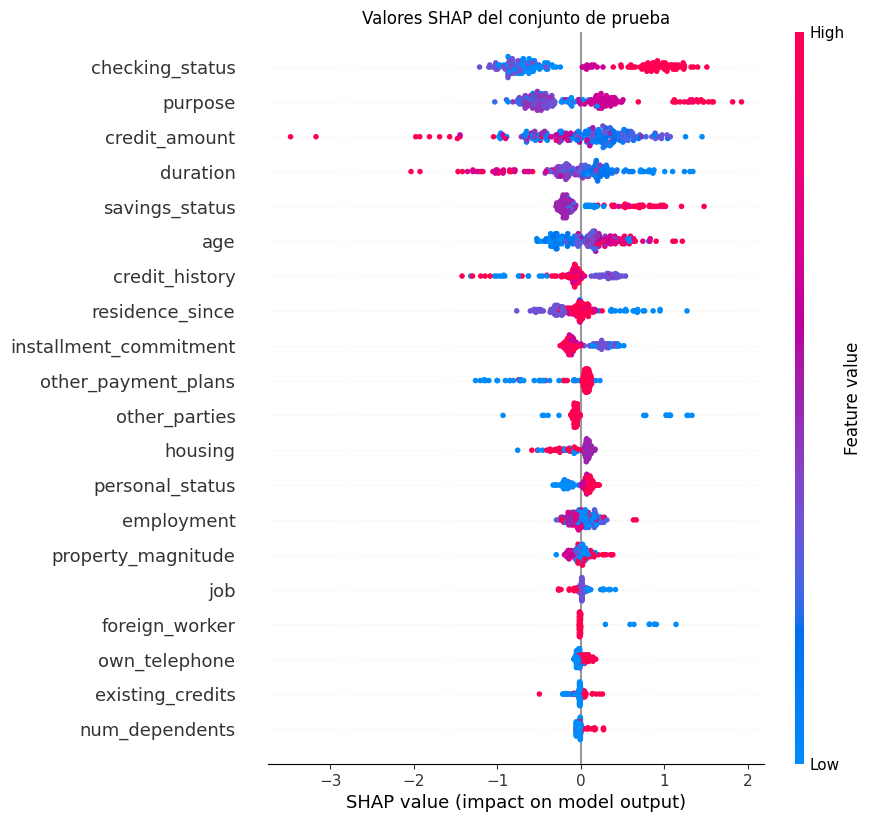

In [8]:
shap.plots.beeswarm(explanation, max_display=20, show=False)
plt.title("Valores SHAP del conjunto de prueba")
plt.show()

**Descripción de las Cascadas**

En el cliente aprobado (p(good) = 0.866) la mayor contribución es `savings_status = no known savings`, que suma 0.92 al log-odds. Le siguen `checking_status = 0<=X<200`, que resta 0.41, y `credit_amount = 2427`, que suma 0.39. En el cliente rechazado (p(good) = 0.087) la mayor contribución es `duration = 36`, que resta 0.93 al log-odds. Le siguen `savings_status = no known savings`, que suma 0.88 y es la única de las tres que favorece la aprobación, y `other_payment_plans = bank`, que resta 0.81.

### Task 2.3. Variables redundantes

Se toma la variable numérica de mayor $I_{j}$ y se crea una copia con ruido, $x_{dup} = x + 0.05\,\sigma_{x}\,\epsilon$, con $\epsilon \sim \mathcal{N}(0,1)$. Se reentrena el modelo con 21 variables y la misma semilla, y se calculan los valores SHAP con la versión intervencional (mismo fondo) y con la dependiente de la trayectoria del árbol (`tree_path_dependent`), que no usa fondo.

In [9]:
top_num = importance.loc[numeric, "I_j (SHAP)"].idxmax()
dup = f"{top_num}_dup"
noise = np.random.default_rng(SEED).standard_normal(len(X))
X_dup = X.copy()
X_dup[dup] = X[top_num] + 0.05 * X[top_num].std() * noise
print(f"Variable duplicada: {top_num} | correlación con la copia: {np.corrcoef(X_dup[top_num], X_dup[dup])[0, 1]:.5f}")

Xd_train, Xd_test, yd_train, _ = split(X_dup, y)
assert Xd_train.index.equals(X_train.index)
model_dup = train_gbm(Xd_train, yd_train)
print(f"AUC en prueba del modelo con 21 variables: {roc_auc_score(y_test, model_dup.predict_proba(Xd_test)[:, 1]):.4f}")

expl_int, _ = tree_shap(model_dup, Xd_test, Xd_train.loc[background.index])
expl_tpd, _ = tree_shap(model_dup, Xd_test)
j_orig, j_dup = Xd_test.columns.get_loc(top_num), Xd_test.columns.get_loc(dup)

rows = []
for name, values in (("intervencional", expl_int.values), ("tree_path_dependent", expl_tpd.values)):
    rows.append({
        "configuración": name,
        "mean |phi_orig|": np.abs(values[:, j_orig]).mean(),
        "mean |phi_copia|": np.abs(values[:, j_dup]).mean(),
        "mean |phi_orig + phi_copia|": np.abs(values[:, j_orig] + values[:, j_dup]).mean(),
    })
dup_table = pd.DataFrame(rows).set_index("configuración")
dup_table["I_j sin copia"] = importance.loc[top_num, "I_j (SHAP)"]
dup_table

Variable duplicada: credit_amount | correlación con la copia: 0.99878
AUC en prueba del modelo con 21 variables: 0.7671


,mean |phi_orig|,mean |phi_copia|,mean |phi_orig + phi_copia|,I_j sin copia
configuración,,,,
intervencional,0.516215,0.42744,0.546004,0.490238
tree_path_dependent,0.380009,0.363073,0.53075,0.490238


**RESULTADOS**

La variable numérica de mayor $I_{j}$ es `credit_amount`, y su copia tiene una correlación de 0.9988 con ella. La tabla se analiza en el Task 2.6.3.

### Task 2.4. KernelSHAP frente a TreeSHAP

Se calculan los valores SHAP de las 10 primeras instancias de prueba con `shap.KernelExplainer` sobre la salida en log-odds, con 2 000 muestras por instancia y sin selección de variables (`l1_reg=False`), para fondos de 10, 50 y 100 instancias (los primeros elementos del fondo del Task 2.2). Cada resultado se compara con TreeSHAP intervencional calculado con el mismo fondo. Antes de medir se ejecuta una corrida de calentamiento que no se cronometra.

In [10]:
X10 = X_test.iloc[:10]
shap.KernelExplainer(f_logit, background.iloc[:10].values).shap_values(X10.values[:1], nsamples=200, l1_reg=False, silent=True)
kernel_rows = []
for size in (10, 50, 100):
    bg = background.iloc[:size]
    start = time.perf_counter()
    kernel = shap.KernelExplainer(f_logit, bg.values)
    phi_kernel = np.asarray(kernel.shap_values(X10.values, nsamples=2000, l1_reg=False, silent=True))
    t_kernel = time.perf_counter() - start

    start = time.perf_counter()
    expl_tree, _ = tree_shap(model, X10, bg)
    t_tree = time.perf_counter() - start

    kernel_rows.append({
        "fondo": size,
        "MAE KernelSHAP vs TreeSHAP": np.abs(phi_kernel.reshape(expl_tree.values.shape) - expl_tree.values).mean(),
        "tiempo KernelSHAP (s)": t_kernel,
        "tiempo TreeSHAP (s)": t_tree,
        "tiempo KernelSHAP por instancia (s)": t_kernel / len(X10),
    })
kernel_table = pd.DataFrame(kernel_rows).set_index("fondo")
kernel_table

,MAE KernelSHAP vs TreeSHAP,tiempo KernelSHAP (s),tiempo TreeSHAP (s),tiempo KernelSHAP por instancia (s)
fondo,,,,
10,0.00230805,1.87559,0.0442314,0.187559
50,0.00524298,3.72374,0.0465627,0.372374
100,0.00433964,5.79818,0.0659236,0.579818


**RESULTADOS**

El error absoluto medio de KernelSHAP frente a TreeSHAP es de 0.0023, 0.0052 y 0.0043 para fondos de 10, 50 y 100 instancias, mientras que el tiempo por instancia sube de 0.19 a 0.37 y a 0.58 segundos. TreeSHAP tarda menos de 0.07 segundos para las 10 instancias en todos los casos.

### Task 2.5. Shapley exacto con la fórmula

Se entrena un segundo modelo con las mismas condiciones y solo seis variables numéricas. Para 5 instancias de prueba y un fondo de 50 instancias se define

$$v(S) = \frac{1}{|B|}\sum_{b \in B} f\big(x_{S}, b_{\bar{S}}\big),$$

se enumeran las $2^{6} = 64$ coaliciones y se aplica

$$\phi_{i} = \sum_{S \subseteq N \setminus \{i\}} \frac{|S|!\,(n - |S| - 1)!}{n!}\,\big[v(S \cup \{i\}) - v(S)\big].$$

Las funciones `coalition_values` y `shapley_from_values` de `src/tabular/shapley.py` implementan ambos pasos sin usar `shap`.

In [11]:
NUM6 = ["duration", "credit_amount", "installment_commitment", "residence_since", "age", "existing_credits"]
model6 = train_gbm(X_train[NUM6], y_train)
f6 = log_odds_fn(model6, NUM6)
bg50 = X_train[NUM6].iloc[bg_idx[:50]]
X5 = X_test[NUM6].iloc[:5]

phi_exact, efficiency = [], []
for x in X5.values:
    v = coalition_values(f6, x, bg50.values)
    phi_i = shapley_from_values(v, len(NUM6))
    phi_exact.append(phi_i)
    efficiency.append(abs(phi_i.sum() - (v[-1] - v[0])))
phi_exact = np.array(phi_exact)

expl6, _ = tree_shap(model6, X5, bg50)
print(f"Error máximo |phi exacto - phi TreeSHAP|:   {np.abs(phi_exact - expl6.values).max():.3e}")
print(f"Error máximo de eficiencia |sum phi - (v(N) - v(vacío))|: {max(efficiency):.3e}")
pd.concat({"exacto": pd.DataFrame(phi_exact, columns=NUM6),
           "TreeSHAP": pd.DataFrame(expl6.values, columns=NUM6)}, axis=1).rename_axis("instancia")

Error máximo |phi exacto - phi TreeSHAP|:   2.142e-08
Error máximo de eficiencia |sum phi - (v(N) - v(vacío))|: 4.996e-16


exacto                                                       \
            duration credit_amount installment_commitment residence_since   
instancia                                                                   
0          -0.553029      0.194368             -0.0729484       -0.119331   
1           -1.65421      0.145274             -0.0402771       -0.109494   
2         -0.0709693      -1.55192               0.054079       0.0500108   
3           0.352572      0.567543             -0.0354141       -0.153521   
4           0.384995      -1.61197              0.0273876      0.00727334   

                                       TreeSHAP                \
                age existing_credits   duration credit_amount   
instancia                                                       
0          0.239534         0.109183  -0.553029      0.194368   
1         -0.331264       -0.0879031   -1.65421      0.145274   
2          0.544702       -0.0985608 -0.0709693      -1.55192   
3          0.398482        -0.135759   0.352572      0.567543   
4          0.923185        -0.104461   0.384995      -1.61197   

                                                                             
          installment_commitment residence_since       age existing_credits  
instancia                                                                    
0                     -0.0729484       -0.119331  0.239534         0.109183  
1                     -0.0402771       -0.109494 -0.331264       -0.0879031  
2                       0.054079       0.0500108  0.544702       -0.0985608  
3                     -0.0354141       -0.153521  0.398482        -0.135759  
4                      0.0273876      0.00727333  0.923185        -0.104461

**RESULTADOS**

Los $\phi_{i}$ calculados con la fórmula de Shapley coinciden con TreeSHAP intervencional con un error máximo de $2.1 \times 10^{-8}$, y su suma iguala $v(N) - v(\emptyset)$ con un error de $5.0 \times 10^{-16}$. Por lo tanto, TreeSHAP intervencional calcula exactamente los valores de Shapley del juego definido por $v(S)$ sobre el fondo.

### Task 2.6. Análisis con los resultados

#### 2.6.1. De log-odds a probabilidad en el cliente rechazado

In [12]:
p_x = sigmoid(f_test[i_bad])
p_base = sigmoid(phi0)
effects = sigmoid(phi0 + phi[i_bad]) - p_base
print(f"p(x) = sigma(f(x))            = {p_x:.6f}")
print(f"sigma(phi_0)                  = {p_base:.6f}")
print(f"suma de efectos individuales  = {effects.sum():.6f}")
print(f"p(x) - sigma(phi_0)           = {p_x - p_base:.6f}")
pd.DataFrame({"phi_j (log-odds)": phi[i_bad], "efecto en probabilidad": effects}, index=cols) \
    .sort_values("phi_j (log-odds)", key=np.abs, ascending=False).head(8)

p(x) = sigma(f(x))            = 0.087144
sigma(phi_0)                  = 0.807017
suma de efectos individuales  = -0.769883
p(x) - sigma(phi_0)           = -0.719873


,phi_j (log-odds),efecto en probabilidad
duration,-0.925967,-0.183436
savings_status,0.876684,0.102473
other_payment_plans,-0.806343,-0.155798
checking_status,-0.583615,-0.107053
purpose,-0.572007,-0.104621
residence_since,-0.538339,-0.0976311
age,-0.510368,-0.0918987
credit_history,-0.40344,-0.0706244


**Respuesta**

Para el cliente rechazado, $p(x) = 0.0871$ y $\sigma(\phi_{0}) = 0.8070$, por lo que el cambio total en probabilidad es $p(x) - \sigma(\phi_{0}) = -0.7199$. La suma de los efectos individuales $\sigma(\phi_{0} + \phi_{j}) - \sigma(\phi_{0})$ es -0.7699, es decir, exagera la caída en 0.05.

Los valores SHAP suman exactamente en log-odds porque esa es la salida que se explicó, $f(x) = \phi_{0} + \sum_{j}\phi_{j}$, y la eficiencia garantiza esa igualdad. La probabilidad es $\sigma(f(x))$ y la sigmoide no es lineal, de modo que $\sigma\big(\phi_{0} + \sum_{j}\phi_{j}\big) \neq \sigma(\phi_{0}) + \sum_{j}\big[\sigma(\phi_{0} + \phi_{j}) - \sigma(\phi_{0})\big]$. Cada efecto individual se mide alrededor de $\phi_{0} = 1.43$, donde la pendiente de la sigmoide es $\sigma(\phi_{0})\big(1 - \sigma(\phi_{0})\big) = 0.156$, pero el log-odds del cliente recorre el tramo hasta -2.35, donde la curva se aplana. Por eso el efecto en probabilidad de una misma contribución en log-odds depende de las demás y los efectos no son aditivos.

#### 2.6.2. Variable con mayor diferencia de ranking

In [13]:
importance["diferencia de ranking"] = (importance["ranking SHAP"] - importance["ranking permutación"]).abs()
var_gap = importance["diferencia de ranking"].idxmax()
print(f"Variable con mayor diferencia de posición: {var_gap}")
display(importance.loc[[var_gap]])

corr = X_train.corr(method="spearman")[var_gap].drop(var_gap)
print(f"Correlaciones de Spearman de '{var_gap}' con las demás variables (entrenamiento), top 5 en valor absoluto:")
corr.reindex(corr.abs().sort_values(ascending=False).index).head(5).to_frame("Spearman")

Variable con mayor diferencia de posición: age


,I_j (SHAP),permutación (media),permutación (desv. est.),ranking SHAP,ranking permutación,diferencia de ranking
age,0.288536,-0.00541667,0.00960711,6,20,14


Correlaciones de Spearman de 'age' con las demás variables (entrenamiento), top 5 en valor absoluto:


,Spearman
housing,-0.312011
employment,0.306383
personal_status,0.272981
residence_since,0.244567
credit_history,-0.199944


**Respuesta**

La variable con mayor diferencia es `age`, sexta por $I_{j}$ (0.289) y última por permutación (-0.0054 con desviación estándar de 0.0096, es decir, indistinguible de cero).

Las dos importancias miden cosas distintas. La importancia por permutación mide cuánto cae el AUC de prueba al barajar la variable, por lo que solo cuenta el uso que mejora el ordenamiento de los clientes según sus etiquetas reales. $I_{j}$ mide el tamaño promedio de la contribución de la variable al log-odds del modelo, sin importar si esa contribución acierta.

**Hipótesis:** el modelo usa `age` con contribuciones grandes, pero parte de esa información se repite en variables correlacionadas y otra parte no generaliza al conjunto de prueba. La correlación de Spearman de `age` con `housing` (-0.31), `employment` (0.31), `personal_status` (0.27) y `residence_since` (0.24) es moderada, por lo que la redundancia explica solo una parte. Que la caída de AUC sea nula con contribuciones de 0.29 en promedio indica que los cortes en `age` mueven las predicciones sin mejorar la separación entre `good` y `bad` en prueba, lo que es compatible con un ajuste al ruido de las 800 solicitudes de entrenamiento.

#### 2.6.3. Crédito de la variable duplicada

Sin copia, `credit_amount` tiene $I_{j} = 0.490$. Con la copia, el crédito se reparte entre las dos variables, de forma desigual en la versión intervencional (0.516 para la original y 0.427 para la copia) y casi igual en la dependiente de la trayectoria (0.380 y 0.363). La contribución conjunta, $|\phi_{\text{orig}} + \phi_{\text{copia}}|$, es de 0.546 y 0.531, algo mayor que el $I_{j}$ original.

El axioma de simetría dice que dos jugadores que aportan lo mismo a toda coalición reciben el mismo valor, por lo que se esperaría un reparto igual. No ocurre porque SHAP explica el modelo y no los datos, y el modelo no trata igual a las dos variables. En cada nodo los árboles eligen la variable con mejor ganancia, y el ruido de la copia hace que unos cortes usen la original y otros la copia, de modo que $f$ no es simétrica en ambas. La versión intervencional además evalúa combinaciones que nunca ocurren en los datos, como un monto original alto con una copia baja, y asigna a cada variable el crédito de los cortes que la usan.

La versión dependiente de la trayectoria reparte de forma más pareja porque, para las variables ausentes, sigue las ramas en proporción al número de muestras de entrenamiento de cada nodo, lo que respeta en parte la correlación. No es exactamente la versión condicional porque solo condiciona a través de los cortes de cada árbol. Usa las proporciones de los nodos como si fueran la distribución condicional y no modela la dependencia entre variables que no aparecen en el mismo camino.

En el mundo real esto implica que un valor SHAP mide cuánto usa el modelo una variable, no cuánto importa el factor que representa. Con variables correlacionadas, el crédito de un mismo factor se divide entre ellas y cada una puede parecer menos importante que el factor completo, por lo que conviene agrupar las variables correlacionadas antes de interpretar su importancia.

#### 2.6.4. Costo computacional

In [14]:
kernel_table["evaluaciones (2000 x fondo)"] = 2000 * kernel_table.index
kernel_table["tiempo por evaluación (µs)"] = 1e6 * kernel_table["tiempo KernelSHAP por instancia (s)"] / kernel_table["evaluaciones (2000 x fondo)"]
display(kernel_table[["evaluaciones (2000 x fondo)", "tiempo KernelSHAP por instancia (s)",
                      "tiempo por evaluación (µs)", "MAE KernelSHAP vs TreeSHAP"]])

X100 = X_test.iloc[:100]
repeats = 50
start = time.perf_counter()
for _ in range(repeats):
    f_logit(X100)
t_100 = (time.perf_counter() - start) / repeats

t_exact_20 = 2 ** 20 * t_100
t_kernel_100 = kernel_table.loc[100, "tiempo KernelSHAP por instancia (s)"]
years_60 = 2 ** 60 * 1e-6 / (365.25 * 24 * 3600)
print(f"Tiempo de una predicción sobre 100 instancias:        {t_100 * 1e3:.3f} ms")
print(f"Shapley exacto, 20 variables (2^20 x t_100):          {t_exact_20:.1f} s = {t_exact_20 / 3600:.2f} h")
print(f"KernelSHAP por instancia con fondo de 100:            {t_kernel_100:.2f} s")
print(f"Razón exacto / KernelSHAP:                            {t_exact_20 / t_kernel_100:.0f}")
print(f"Shapley exacto, 60 variables, 1 µs por evaluación:    {years_60:,.0f} años")

,evaluaciones (2000 x fondo),tiempo KernelSHAP por instancia (s),tiempo por evaluación (µs),MAE KernelSHAP vs TreeSHAP
fondo,,,,
10,20000,0.187559,9.37795,0.00230805
50,100000,0.372374,3.72374,0.00524298
100,200000,0.579818,2.89909,0.00433964


Tiempo de una predicción sobre 100 instancias:        2.488 ms
Shapley exacto, 20 variables (2^20 x t_100):          2608.7 s = 0.72 h
KernelSHAP por instancia con fondo de 100:            0.58 s
Razón exacto / KernelSHAP:                            4499
Shapley exacto, 60 variables, 1 µs por evaluación:    36,534 años


**Respuesta**

El tiempo no crece como el modelo de costo propuesto. Al pasar de un fondo de 10 a 50 y a 100 instancias, el número de evaluaciones del modelo crece 5 y 10 veces, pero el tiempo por instancia crece solo 2.0 y 3.1 veces (0.19, 0.37 y 0.58 segundos). El tiempo por evaluación baja de 9.4 a 2.9 µs, lo que indica un costo fijo por muestra (generar coaliciones, armar los datos y resolver la regresión ponderada) que domina con fondos pequeños. Con fondos grandes el costo se acerca al régimen proporcional.

El error tampoco baja al aumentar el fondo (0.0023, 0.0052 y 0.0043). Como cada KernelSHAP se compara con TreeSHAP calculado con el mismo fondo, el tamaño del fondo no cambia el valor a estimar, y el error depende sobre todo del muestreo de 2 000 coaliciones de las $2^{20}$ posibles.

Una predicción sobre 100 instancias tarda 2.49 ms. El cálculo exacto de una instancia del modelo de 20 variables requiere $2^{20}$ evaluaciones de $v(S)$, cada una sobre el fondo de 100, lo que da $2^{20} \times 2.49 \text{ ms} \approx 2\,609$ s, unas 0.72 horas. KernelSHAP tarda 0.58 s por instancia con el mismo fondo, unas 4 500 veces menos. Con 60 variables y un microsegundo por evaluación, las $2^{60}$ evaluaciones tomarían unos 36 534 años.

## Task 3 - LIME y contrafactuales

### Task 3.1. LIME desde cero

La representación interpretable usa las 20 variables originales. Cada variable está presente (conserva el valor de la instancia) o ausente (toma un valor al azar de su columna en entrenamiento). La función `lime_explain` de `src/tabular/lime_tabular.py` sigue estos pasos.

1. Genera $N$ vectores binarios $z'$ con componentes iguales a 1 con probabilidad 0.5 y construye las entradas $z$.
2. Explica la probabilidad de `good` y pondera cada muestra con $\pi_{x}(z) = \exp\left(-\frac{D^{2}}{\sigma^{2}}\right)$, donde $D^{2}$ es el número de variables ausentes y $\sigma = \sigma_{rel}\sqrt{d'}$ con $d' = 20$.
3. Ajusta $w = \left({Z'}^{\intercal}\Pi Z' + \lambda I\right)^{-1}{Z'}^{\intercal}\Pi y$ con una columna de unos para el intercepto. **El intercepto no se penaliza** (su entrada en $\lambda I$ es cero).
4. Conserva las $K$ variables de mayor $|w|$, vuelve a ajustar solo con ellas y calcula la fidelidad ponderada $R_{w}^{2}$.

| Parámetro | Valor |
| :-------- | :---: |
| Número de muestras $N$ | 5 000 |
| Variables que se conservan $K$ | 5 |
| Regularización $\lambda$ | 1.0 |
| Ancho relativo del kernel $\sigma_{rel}$ | 0.75 |

Se explican tres clientes de prueba: el aprobado del Task 2.2 (probabilidad mayor que 0.8), el rechazado del Task 2.2 y el primero con probabilidad entre 0.45 y 0.55.

In [15]:
X_train_arr, X_test_arr = X_train.values, X_test.values
mid = np.flatnonzero((p_test > 0.45) & (p_test < 0.55))
i_mid = int(mid[0]) if mid.size else int(np.argmin(np.abs(p_test - 0.5)))
clients = {"aprobado": i_good, "rechazado": i_bad, "frontera": i_mid}

lime_results = {}
for label, i in clients.items():
    lime_results[label] = lime_explain(f_prob, X_test_arr[i], X_train_arr, n_samples=5000, k=5, lam=1.0,
                                       sigma_rel=0.75, rng=np.random.default_rng(SEED))
    r = lime_results[label]
    print(f"Cliente {label} (posición {i}, p(good) = {p_test[i]:.4f}) | intercepto = {r['intercept']:.4f} | R²_w = {r['r2_w']:.4f}")
    display(pd.DataFrame({"variable": [cols[j] for j in r["features"]],
                          "valor": [X_test_display.iloc[i, j] for j in r["features"]],
                          "coeficiente": r["coef"]}))

Cliente aprobado (posición 0, p(good) = 0.8664) | intercepto = 0.6695 | R²_w = 0.1714


,variable,valor,coeficiente
0,savings_status,no known savings,0.140518
1,credit_amount,2427,0.0738348
2,checking_status,0<=X<200,-0.0633058
3,residence_since,2,-0.038059
4,duration,18,0.032983


Cliente rechazado (posición 1, p(good) = 0.0871) | intercepto = 0.5510 | R²_w = 0.2268


,variable,valor,coeficiente
0,savings_status,no known savings,0.141357
1,other_payment_plans,bank,-0.132438
2,checking_status,0<=X<200,-0.112065
3,duration,36,-0.106227
4,age,29,-0.102166


Cliente frontera (posición 22, p(good) = 0.4663) | intercepto = 0.6985 | R²_w = 0.1669


,variable,valor,coeficiente
0,checking_status,0<=X<200,-0.147717
1,credit_amount,1245,-0.116603
2,credit_history,critical/other existing credit,0.0751707
3,residence_since,2,-0.0521981
4,purpose,radio/tv,0.0453069


**RESULTADOS**

En los tres clientes la fidelidad ponderada es baja ($R_{w}^{2}$ de 0.171, 0.227 y 0.167), es decir, el modelo lineal local explica menos de una cuarta parte de la variación ponderada de la probabilidad. `checking_status` aparece en los tres clientes, siempre con coeficiente negativo, y `savings_status` aparece en el aprobado y en el rechazado con coeficiente positivo.

### Task 3.2. Estabilidad de LIME en el cliente rechazado

Para cada combinación de $N$ y $\sigma_{rel}$ se ejecuta LIME 20 veces con semillas distintas. Se reporta el índice de Jaccard promedio entre los conjuntos de las $K$ variables principales de todos los pares de corridas y el tamaño efectivo de muestra promedio $N_{ef} = \frac{\left(\sum_{n}\pi_{n}\right)^{2}}{\sum_{n}\pi_{n}^{2}}$.

In [16]:
N_VALUES = (500, 2000, 5000)
SIGMA_VALUES = (0.5, 0.75, 1.5)
RUN_SEEDS = range(SEED, SEED + 20)
x_bad = X_test_arr[i_bad]


def lime_stability(n_samples, sigma_rel, seeds=RUN_SEEDS):
    runs = [lime_explain(f_prob, x_bad, X_train_arr, n_samples=n_samples, sigma_rel=sigma_rel,
                         rng=np.random.default_rng(s)) for s in seeds]
    return mean_pairwise_jaccard([set(r["features"]) for r in runs]), np.mean([r["n_eff"] for r in runs])


jaccard_table = pd.DataFrame(index=pd.Index(N_VALUES, name="N"), columns=SIGMA_VALUES, dtype=float)
neff_table = jaccard_table.copy()
for n_samples in N_VALUES:
    for sigma_rel in SIGMA_VALUES:
        jaccard_table.loc[n_samples, sigma_rel], neff_table.loc[n_samples, sigma_rel] = lime_stability(n_samples, sigma_rel)
jaccard_table.columns.name = neff_table.columns.name = "sigma_rel"
print("Jaccard promedio")
display(jaccard_table)
print("N_ef promedio")
display(neff_table)

Jaccard promedio


sigma_rel,0.5,0.75,1.5
N,,,
500,0.616792,0.630388,0.596074
2000,0.773935,0.829073,0.845865
5000,0.857895,0.907018,0.907018


N_ef promedio


sigma_rel,0.5,0.75,1.5
N,,,
500,409.684,480.521,498.756
2000,1639.42,1922.5,1995.06
5000,4099.94,4806.28,4987.65


**RESULTADOS**

El Jaccard sube con $N$ en los tres anchos, de alrededor de 0.6 con $N = 500$ a valores entre 0.86 y 0.91 con $N = 5\,000$. $N_{ef}$ es una fracción de $N$ que crece con $\sigma_{rel}$, de alrededor de 82%, 96% y 100% para $\sigma_{rel}$ de 0.5, 0.75 y 1.5.

### Task 3.3. LIME frente a SHAP

**1.** Para cada cliente se calcula la correlación de Spearman entre $|w|$ de LIME (ajuste sobre las 20 variables) y $|\phi|$ de SHAP del Task 2.2, y la coincidencia entre las tres variables principales de cada método.

In [17]:
rows = []
for label, i in clients.items():
    w_abs = np.abs(lime_results[label]["coef_full"])
    phi_abs = np.abs(phi[i])
    top_lime = [cols[j] for j in np.argsort(-w_abs)[:3]]
    top_shap = [cols[j] for j in np.argsort(-phi_abs)[:3]]
    rows.append({
        "cliente": label,
        "Spearman |w| vs |phi|": spearmanr(w_abs, phi_abs).statistic,
        "top-3 LIME": top_lime,
        "top-3 SHAP": top_shap,
        "coincidencias": len(set(top_lime) & set(top_shap)),
    })
pd.DataFrame(rows).set_index("cliente")

,Spearman |w| vs |phi|,top-3 LIME,top-3 SHAP,coincidencias
cliente,,,,
aprobado,0.723308,"[savings_status, credit_amount, checking_status]","[savings_status, checking_status, credit_amount]",3
rechazado,0.95188,"[savings_status, other_payment_plans, checking...","[duration, savings_status, other_payment_plans]",2
frontera,0.792481,"[checking_status, credit_amount, credit_history]","[checking_status, credit_amount, credit_history]",3


**RESULTADOS**

La correlación de Spearman entre $|w|$ y $|\phi|$ es de 0.72, 0.95 y 0.79 para los clientes aprobado, rechazado y de frontera. En el aprobado y el de frontera coinciden las tres variables principales, y en el rechazado coinciden dos de tres, ya que SHAP pone `duration` en primer lugar y LIME no la incluye entre sus tres primeras.

**2.** Para el cliente rechazado se ajusta LIME con $K \in \{3, 5, 10, 20\}$, con las mismas muestras, y se reporta $R_{w}^{2}$.

In [18]:
r2_by_k = pd.Series({k: lime_explain(f_prob, x_bad, X_train_arr, n_samples=5000, k=k, lam=1.0, sigma_rel=0.75,
                                     rng=np.random.default_rng(SEED))["r2_w"]
                     for k in (3, 5, 10, 20)}, name="R²_w")
r2_by_k.index.name = "K"
r2_by_k.to_frame()

,R²_w
K,
3,0.158303
5,0.226817
10,0.293392
20,0.300791


**RESULTADOS**

$R_{w}^{2}$ crece de 0.158 con $K = 3$ a 0.227 con $K = 5$ y a 0.293 con $K = 10$, y casi no cambia al pasar a $K = 20$ (0.301).

### Task 3.4. Explicaciones contrafactuales

Se buscan contrafactuales para el cliente rechazado con 20 000 candidatos. Cada candidato cambia un subconjunto aleatorio de entre 1 y 3 variables accionables (`duration`, `credit_amount`, `installment_commitment`, `checking_status`, `savings_status`) con valores observados en entrenamiento. Las variables `age`, `personal_status` y `foreign_worker` son inmutables. Un candidato es válido si su probabilidad de `good` es al menos $\theta = 0.5$, y su distancia al original es

$$d(x, x') = \sum_{j \in \text{num}}\frac{\left|x_{j} - x_{j}'\right|}{\operatorname{MAD}_{j}} + \sum_{j \in \text{cat}}\mathbb{1}\left[x_{j} \neq x_{j}'\right].$$

Se elige el candidato válido más cercano y luego dos más con conjuntos de variables cambiadas distintos. La proximidad y la dispersión se calculan sobre los tres contrafactuales elegidos.

In [19]:
ACTIONABLE = ["duration", "credit_amount", "installment_commitment", "checking_status", "savings_status"]
IMMUTABLE = ["age", "personal_status", "foreign_worker"]
THETA = 0.5
actionable_idx = [cols.index(c) for c in ACTIONABLE]
numeric_idx = [cols.index(c) for c in numeric]
categorical_idx = [cols.index(c) for c in categorical]
scale = mad_scale(X_train_arr)


def counterfactual_search(max_changes, n_candidates=20000):
    cands = generate_candidates(x_bad, X_train_arr, actionable_idx, n_candidates, max_changes,
                                np.random.default_rng(SEED))
    probs = f_prob(cands)
    return cands, probs, probs >= THETA, distance(x_bad, cands, numeric_idx, categorical_idx, scale)


max_changes = 3
cands, cand_probs, valid, dist = counterfactual_search(max_changes)
if not valid.any():
    max_changes = 5
    print("Ningún candidato válido con 3 cambios; se aumenta el máximo a 5 variables.")
    cands, cand_probs, valid, dist = counterfactual_search(max_changes)
chosen = select_diverse(x_bad, cands, dist, valid, n_select=3)

rows = []
for rank, idx in enumerate(chosen, start=1):
    for j in np.flatnonzero(cands[idx] != x_bad):
        rows.append({
            "contrafactual": rank,
            "variable": cols[j],
            "original": decode(x_bad[j], cols[j], encoder, categorical),
            "nuevo": decode(cands[idx, j], cols[j], encoder, categorical),
            "distancia": dist[idx],
            "p(good)": cand_probs[idx],
        })
print(f"Cliente rechazado: p(good) = {p_test[i_bad]:.4f} | máximo de variables cambiadas = {max_changes}")
print(f"Validez (fracción de candidatos válidos): {valid.mean():.4f} ({valid.sum()} de {len(valid)})")
print(f"Proximidad promedio (distancia media):    {dist[chosen].mean():.4f}")
print(f"Dispersión (variables cambiadas, media):  {np.mean([(cands[i] != x_bad).sum() for i in chosen]):.2f}")
print("MAD de las variables numéricas accionables:",
      {c: round(scale[cols.index(c)], 3) for c in ACTIONABLE if c in numeric})
pd.DataFrame(rows).set_index(["contrafactual", "variable"])

Cliente rechazado: p(good) = 0.0871 | máximo de variables cambiadas = 3
Validez (fracción de candidatos válidos): 0.0008 (16 de 20000)
Proximidad promedio (distancia media):    5.2681
Dispersión (variables cambiadas, media):  3.00
MAD de las variables numéricas accionables: {'duration': np.float64(6.0), 'credit_amount': np.float64(1057.5), 'installment_commitment': np.float64(1.0)}


original        nuevo  distancia  \
contrafactual variable                                                   
1             checking_status         0<=X<200  no checking    2.19858   
              duration                      36           30    2.19858   
              credit_amount               3990         3780    2.19858   
2             checking_status         0<=X<200  no checking          4   
              duration                      36           30          4   
              installment_commitment         3            1          4   
3             duration                      36           28    9.60567   
              credit_amount               3990        10623    9.60567   
              installment_commitment         3            1    9.60567   

                                      p(good)  
contrafactual variable                         
1             checking_status         0.52986  
              duration                0.52986  
              credit_amount           0.52986  
2             checking_status        0.519038  
              duration               0.519038  
              installment_commitment 0.519038  
3             duration               0.644344  
              credit_amount          0.644344  
              installment_commitment 0.644344

**RESULTADOS**

Con un máximo de tres cambios, 16 de los 20 000 candidatos son válidos (validez de 0.0008), por lo que no fue necesario aumentar el máximo a cinco. Los tres contrafactuales elegidos cambian tres variables cada uno (dispersión de 3.00) y tienen una distancia promedio de 5.27. Los tres reducen `duration` de 36 a 28 o 30 meses. El más cercano (distancia 2.20) además cambia `checking_status` a `no checking` y baja `credit_amount` a 3 780, con lo que la probabilidad de `good` sube de 0.087 a 0.530.

### Task 3.5. Análisis con los resultados

#### 3.5.1. Relación entre $N_{ef}$ y Jaccard

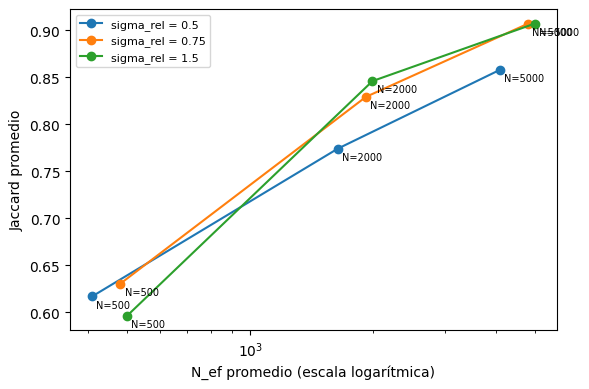

In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
for sigma_rel in SIGMA_VALUES:
    ax.plot(neff_table[sigma_rel], jaccard_table[sigma_rel], marker="o", label=f"sigma_rel = {sigma_rel}")
    for n_samples in N_VALUES:
        ax.annotate(f"N={n_samples}", (neff_table.loc[n_samples, sigma_rel], jaccard_table.loc[n_samples, sigma_rel]),
                    fontsize=7, xytext=(3, -8), textcoords="offset points")
ax.set_xscale("log")
ax.set_xlabel("N_ef promedio (escala logarítmica)")
ax.set_ylabel("Jaccard promedio")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Para estimar cuántas muestras se necesitan para un Jaccard de 0.9 con $\sigma_{rel} = 0.75$ se ajusta una ley de potencia a la inestabilidad, $1 - J = a N^{-b}$, que es una recta en escala log-log, con los tres puntos de la tabla. Después se verifica la estimación con 20 corridas adicionales en el $N$ estimado y en dos tamaños mayores.

In [21]:
j_075 = jaccard_table[0.75].astype(float)
instability = np.clip(1 - j_075.values, 1e-3, None)
slope, intercept = np.polyfit(np.log(N_VALUES), np.log(instability), 1)
b, a = -slope, np.exp(intercept)
print(f"Ajuste: 1 - J = {a:.4g} * N^(-{b:.4f})")
if b <= 0:
    print("La inestabilidad no disminuye con N; la extrapolación no es válida.")
else:
    n_target = (a / 0.1) ** (1 / b)
    n_verify = int(min(np.ceil(n_target / 100) * 100, 500_000))
    print(f"N estimado para Jaccard = 0.9: {n_target:,.0f} (se verifica con N = {n_verify:,})")
    for n_check in (n_verify, 10_000, 20_000):
        j_check, neff_check = lime_stability(n_check, 0.75)
        print(f"Verificación con N = {n_check:>6,}: Jaccard = {j_check:.4f}, N_ef = {neff_check:,.0f}, "
              f"predicción del ajuste = {1 - a * n_check ** (-b):.4f}")

Ajuste: 1 - J = 15.23 * N^(-0.5959)
N estimado para Jaccard = 0.9: 4,604 (se verifica con N = 4,700)
Verificación con N =  4,700: Jaccard = 0.8386, N_ef = 4,518, predicción del ajuste = 0.9012
Verificación con N = 10,000: Jaccard = 0.9667, N_ef = 9,614, predicción del ajuste = 0.9370
Verificación con N = 20,000: Jaccard = 1.0000, N_ef = 19,227, predicción del ajuste = 0.9583


**Respuesta**

La figura muestra que el Jaccard crece con $N_{ef}$ casi sobre una misma curva para los tres anchos. Con $N$ fijo, un $\sigma_{rel}$ menor reduce $N_{ef}$ y también el Jaccard. Por ejemplo, con $N = 5\,000$ el Jaccard es 0.858 con $N_{ef} = 4\,100$ y 0.907 con $N_{ef} = 4\,806$. La estabilidad depende del número de muestras que realmente pesan en el ajuste, no del número generado.

Para la extrapolación se ajustó $1 - J = a N^{-b}$, con el supuesto de que la inestabilidad proviene del error de muestreo de los coeficientes, que disminuye como una potencia de $N$. El exponente estimado, $b = 0.60$, es cercano al 0.5 de un error estándar que baja como $\frac{1}{\sqrt{N}}$, lo que respalda la forma elegida. El ajuste predice un Jaccard de 0.9 con unas 4 600 muestras.

La verificación no confirma esa estimación. Con $N = 4\,700$ el Jaccard es 0.839, por debajo del 0.901 predicho, mientras que con $N = 10\,000$ es 0.967 y con $N = 20\,000$ es 1.000. El Jaccard con $K = 5$ cambia a saltos, ya que solo se mueve cuando la quinta y la sexta variable intercambian lugar, y cerca de 0.9 depende de pocas corridas, por lo que tres puntos no bastan para ubicar con precisión el cruce. Con los datos disponibles, un Jaccard de 0.9 se alcanza de forma estable entre 5 000 y 10 000 muestras, y 10 000 es la cantidad recomendada para este cliente.

#### 3.5.2. Mayor discrepancia entre LIME y SHAP

Como LIME explica probabilidades y SHAP explica log-odds, se comparan las importancias relativas, $\frac{|w_{j}|}{\sum_{k}|w_{k}|}$ frente a $\frac{|\phi_{j}|}{\sum_{k}|\phi_{k}|}$, y se toma el cliente y la variable con mayor diferencia absoluta.

In [22]:
gaps = pd.DataFrame({
    label: np.abs(lime_results[label]["coef_full"]) / np.abs(lime_results[label]["coef_full"]).sum()
    - np.abs(phi[i]) / np.abs(phi[i]).sum()
    for label, i in clients.items()
}, index=cols)
client_gap, var_disc = gaps.abs().stack().idxmax()[::-1]
i_disc, j_disc = clients[client_gap], cols.index(var_disc)
r = lime_results[client_gap]
print(f"Mayor discrepancia: cliente {client_gap}, variable {var_disc}")
print(f"  importancia relativa LIME - SHAP = {gaps.loc[var_disc, client_gap]:+.4f}")
print(f"  w_LIME = {r['coef_full'][j_disc]:+.4f} (probabilidad) | phi_SHAP = {phi[i_disc, j_disc]:+.4f} (log-odds)")
print(f"  valor del cliente = {X_test_display.iloc[i_disc, j_disc]}")

Mayor discrepancia: cliente frontera, variable duration
  importancia relativa LIME - SHAP = -0.0528
  w_LIME = +0.0076 (probabilidad) | phi_SHAP = -0.2196 (log-odds)
  valor del cliente = 18.0


**Prueba 1.** Se repite LIME para ese cliente con varios valores de $\sigma_{rel}$ y se observa si la discrepancia cambia.

In [23]:
phi_share = np.abs(phi[i_disc, j_disc]) / np.abs(phi[i_disc]).sum()
rows = []
for sigma_rel in (0.25, 0.5, 0.75, 1.5):
    res = lime_explain(f_prob, X_test_arr[i_disc], X_train_arr, n_samples=5000, sigma_rel=sigma_rel,
                       rng=np.random.default_rng(SEED))
    w_share = np.abs(res["coef_full"][j_disc]) / np.abs(res["coef_full"]).sum()
    rows.append({"sigma_rel": sigma_rel, "w_LIME": res["coef_full"][j_disc],
                 "importancia relativa LIME": w_share, "importancia relativa SHAP": phi_share,
                 "discrepancia": w_share - phi_share, "R²_w (K=5)": res["r2_w"], "N_ef": res["n_eff"]})
pd.DataFrame(rows).set_index("sigma_rel")

,w_LIME,importancia relativa LIME,importancia relativa SHAP,discrepancia,R²_w (K=5),N_ef
sigma_rel,,,,,,
0.25,0.00225456,0.00525684,0.0642765,-0.0590196,0.173489,289.383
0.5,0.00663506,0.010057,0.0642765,-0.0542194,0.173205,4101.88
0.75,0.00758357,0.0114662,0.0642765,-0.0528103,0.166937,4808.43
1.5,0.00797374,0.0120554,0.0642765,-0.0522211,0.162621,4987.82


**Prueba 2.** Se grafica la probabilidad de `good` del cliente al variar solo esa variable entre los valores observados en entrenamiento (curva ICE). Como referencia se agrega el promedio de esa curva sobre el fondo de 100 instancias (dependencia parcial). Si la curva del cliente difiere en forma de la curva promedio, hay indicios de interacción.

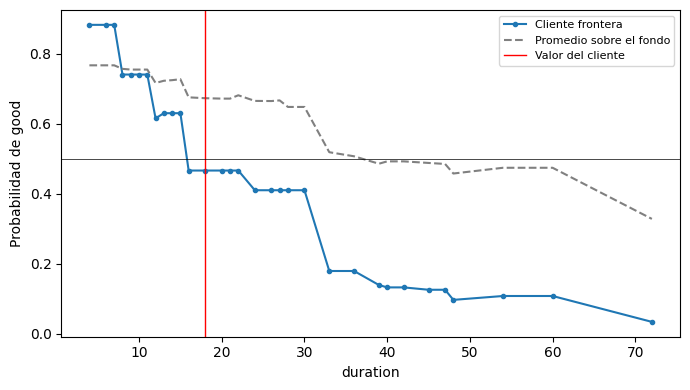

Rango de la curva del cliente: 0.0333 a 0.8830 | rango del promedio: 0.3279 a 0.7672


In [24]:
values = np.unique(X_train_arr[:, j_disc])
if values.size > 60:
    values = np.unique(np.quantile(X_train_arr[:, j_disc], np.linspace(0, 1, 60)))

grid = np.repeat(X_test_arr[i_disc][None], values.size, axis=0)
grid[:, j_disc] = values
ice = f_prob(grid)

bg_arr = background.values
pdp = np.array([f_prob(np.where(np.arange(len(cols)) == j_disc, v, bg_arr)).mean() for v in values])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(values, ice, marker="o", ms=3, label=f"Cliente {client_gap}")
ax.plot(values, pdp, ls="--", color="gray", label="Promedio sobre el fondo")
ax.axvline(X_test_arr[i_disc, j_disc], color="red", lw=1, label="Valor del cliente")
ax.axhline(THETA, color="black", lw=0.5)
ax.set_xlabel(f"{var_disc} (código)" if var_disc in categorical else var_disc)
ax.set_ylabel("Probabilidad de good")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
if var_disc in categorical:
    print("Códigos:", dict(enumerate(encoder.categories_[categorical.index(var_disc)])))
print(f"Rango de la curva del cliente: {ice.min():.4f} a {ice.max():.4f} | rango del promedio: {pdp.min():.4f} a {pdp.max():.4f}")

**RESULTADOS**

La mayor discrepancia está en el cliente de frontera y la variable `duration`. SHAP le asigna -0.220 en log-odds (6.4% de la importancia total del cliente), mientras que LIME le da un coeficiente de +0.008 (1.1%).

La primera prueba descarta la localidad. Al reducir $\sigma_{rel}$ de 1.5 a 0.25 la discrepancia no baja, sino que pasa de -0.052 a -0.059, y $R_{w}^{2}$ casi no cambia (de 0.163 a 0.173).

La segunda prueba muestra la causa. La probabilidad del cliente baja a saltos con `duration`, de 0.88 con plazos cortos a 0.03 con 72 meses, y el valor del cliente (18 meses) queda en medio de ese descenso. LIME reemplaza la variable ausente por un plazo al azar de entrenamiento, que a veces es más corto y sube la probabilidad y a veces es más largo y la baja, de modo que los efectos se compensan y una recta no puede representarlos. Además, la curva del cliente recorre de 0.03 a 0.88, mientras que el promedio sobre el fondo solo va de 0.33 a 0.77. El efecto de `duration` en este cliente es mucho más fuerte que en el cliente promedio, lo que indica una interacción con sus otras variables. La discrepancia se debe a la relación no lineal, reforzada por una interacción, y no a la localidad.

#### 3.5.3. Elección de $K$

Se elige $K = 10$. Por fidelidad, $R_{w}^{2}$ sube 0.069 de $K = 3$ a $K = 5$ y 0.067 de $K = 5$ a $K = 10$, pero solo 0.007 de $K = 10$ a $K = 20$. Con 10 variables se obtiene el 97% de la fidelidad máxima del modelo lineal (0.293 de 0.301), y las 10 variables restantes solo agregan complejidad. Por comprensibilidad, 10 coeficientes son manejables para un analista, aunque a la persona solicitante convendría mostrarle solo las primeras.

Para una decisión de crédito se propone una fidelidad mínima de $R_{w}^{2} = 0.8$. La explicación se usa para justificar una decisión que afecta a una persona, y si el modelo local deja sin explicar más de una quinta parte de la variación, las razones entregadas pueden no ser las que realmente producen la decisión. Este umbral es una elección de política y no un resultado del laboratorio. Con este cliente ningún $K$ se acerca a ese mínimo, ya que incluso $K = 20$ llega a 0.301, y reducir $\sigma_{rel}$ tampoco lo mejora (Task 3.5.2). Si no se alcanza, no se entregaría la explicación de LIME. En su lugar se usaría SHAP, cuya eficiencia se verificó con un error de $9.7 \times 10^{-8}$, o un modelo interpretable por diseño, y se revisaría la representación interpretable, por ejemplo con intervalos para las variables numéricas, porque la representación de presente o ausente no captura efectos como el de `duration`.

#### 3.5.4 · Contrafactuales frente a SHAP en el cliente rechazado

Para las tres variables de mayor $|\phi|$ del cliente rechazado se indica si son accionables y se calcula el mejor cambio individual posible, probando todos los valores observados en entrenamiento y cambiando solo esa variable.

In [25]:
changed_vars = sorted({cols[j] for idx in chosen for j in np.flatnonzero(cands[idx] != x_bad)})
top3_bad = [cols[j] for j in np.argsort(-np.abs(phi[i_bad]))[:3]]
print(f"Variables que cambian en los contrafactuales: {changed_vars}")
print(f"Tres variables de mayor |phi| del cliente rechazado: {top3_bad}")

rows = []
for var in top3_bad:
    j = cols.index(var)
    options = np.unique(X_train_arr[:, j])
    grid = np.repeat(x_bad[None], options.size, axis=0)
    grid[:, j] = options
    probs = f_prob(grid)
    dists = distance(x_bad, grid, numeric_idx, categorical_idx, scale)
    best = int(np.argmax(probs))
    rows.append({
        "variable": var,
        "phi_j": phi[i_bad, j],
        "tipo": "inmutable" if var in IMMUTABLE else ("accionable" if var in ACTIONABLE else "no accionable"),
        "valor actual": decode(x_bad[j], var, encoder, categorical),
        "mejor valor": decode(options[best], var, encoder, categorical),
        "p(good) máxima": probs[best],
        "distancia del mejor valor": dists[best],
        "MAD": scale[j] if var in numeric else np.nan,
    })
pd.DataFrame(rows).set_index("variable")

Variables que cambian en los contrafactuales: ['checking_status', 'credit_amount', 'duration', 'installment_commitment']
Tres variables de mayor |phi| del cliente rechazado: ['duration', 'savings_status', 'other_payment_plans']


,phi_j,tipo,valor actual,mejor valor,p(good) máxima,distancia del mejor valor,MAD
variable,,,,,,,
duration,-0.925967,accionable,36,27,0.292547,1.5,6
savings_status,0.876684,accionable,no known savings,>=1000,0.0934432,1,NaN
other_payment_plans,-0.806343,no accionable,bank,none,0.210332,1,NaN


**Respuesta**

Los contrafactuales cambian `duration`, `credit_amount`, `installment_commitment` y `checking_status`, y las tres variables de mayor $|\phi|$ del cliente son `duration` (-0.93), `savings_status` (+0.88) y `other_payment_plans` (-0.81). Solo `duration` aparece en ambos grupos, y está en los tres contrafactuales.

`savings_status` tiene un $|\phi|$ alto pero no aparece en los contrafactuales. Su contribución es positiva, es decir, el valor actual (`no known savings`) ya favorece al cliente y no deja margen para mejorar. El mejor cambio posible (`>=1000`) cuesta 1 en la distancia y sube la probabilidad solo de 0.087 a 0.093, un efecto muy pequeño frente al 0.5 requerido. `other_payment_plans` tampoco aparece porque no es accionable en esta búsqueda, y aun cambiándola a `none` la probabilidad llegaría solo a 0.21. Ninguna variable por sí sola alcanza el umbral, ya que el mejor cambio de `duration` (a 27 meses) llega a 0.29, y por eso todos los contrafactuales combinan tres cambios.

SHAP responde a la pregunta de cuánto aportó cada variable a esta predicción frente al promedio del fondo. El contrafactual responde a la pregunta de qué cambio mínimo y factible haría que la decisión fuera distinta. Una variable puede pesar mucho en la primera pregunta y no servir para la segunda.